# Trajectory Sampling Stability

This analysis evaluates whether regional cortical depth profiles remain stable when fewer trajectories are sampled.

For each subject and cortical region:

1. The mean profile from all available trajectories is used as the reference.
2. Random subsets of 10, 100, and 1000 trajectories are sampled.
3. Each sampling size is repeated 100 times.
4. Each sampled profile is compared with the full regional profile using:
   - Mean absolute error (MAE)
   - Root mean squared error (RMSE)
   - Pearson correlation

The analysis is performed for both S00775 and D0007 using the same workflow.

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import pearsonr


SUBJECTS = {
    "S00775": Path(
        "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/"
        "S00775/analysis/profiles"
    ),
    "D0007": Path(
        "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/"
        "D0007/analysis/profiles"
    ),
}

METRIC = "adc"

SAMPLE_SIZES = [
    10,
    100,
    1000,
]

N_REPEATS = 100
RANDOM_SEED = 42

## Sampling Functions

Each regional profile file contains:

- rows: cortical trajectories
- columns: cortical depth samples

The full mean profile is calculated using all trajectories.

For each sampling size, trajectories are randomly selected without replacement and averaged to generate a sampled regional profile.

In [7]:
def load_profile(file_path):
    values = np.loadtxt(
        file_path,
        delimiter=",",
    )

    if values.ndim == 1:
        values = values.reshape(1, -1)

    return values


def compare_profiles(sample_profile, full_profile):
    mae = np.mean(
        np.abs(sample_profile - full_profile)
    )

    rmse = np.sqrt(
        np.mean(
            (sample_profile - full_profile) ** 2
        )
    )

    if np.std(sample_profile) == 0 or np.std(full_profile) == 0:
        correlation = np.nan
    else:
        correlation = pearsonr(
            sample_profile,
            full_profile,
        )[0]

    return mae, rmse, correlation

## Run Sampling Stability

The same sampling procedure is applied to all available cortical regions for both subjects.

Sampling sizes larger than the number of available trajectories in a region are skipped.

In [8]:
rng = np.random.default_rng(
    RANDOM_SEED
)

results = []

for subject, profile_dir in SUBJECTS.items():

    profile_files = sorted(
        profile_dir.glob(
            f"{subject}_*_{METRIC}.csv"
        )
    )

    print(
        subject,
        "profile files:",
        len(profile_files),
    )

    for file_path in profile_files:

        name = file_path.stem

        prefix = f"{subject}_"
        suffix = f"_{METRIC}"

        region_label = name[
            len(prefix):-len(suffix)
        ]

        hemisphere, region = region_label.split(
            "_",
            1,
        )

        values = load_profile(
            file_path
        )

        total_trajectories = values.shape[0]

        full_profile = values.mean(
            axis=0
        )

        for sample_n in SAMPLE_SIZES:

            if sample_n > total_trajectories:
                continue

            for repeat in range(N_REPEATS):

                indices = rng.choice(
                    total_trajectories,
                    size=sample_n,
                    replace=False,
                )

                sample_profile = values[
                    indices
                ].mean(
                    axis=0
                )

                (
                    mae,
                    rmse,
                    correlation,
                ) = compare_profiles(
                    sample_profile,
                    full_profile,
                )

                results.append(
                    {
                        "subject": subject,
                        "hemisphere": hemisphere,
                        "region": region,
                        "total_trajectories": total_trajectories,
                        "sample_n": sample_n,
                        "repeat": repeat + 1,
                        "mae": mae,
                        "rmse": rmse,
                        "correlation": correlation,
                    }
                )


results_df = pd.DataFrame(
    results
)

results_df

S00775 profile files: 68
D0007 profile files: 68


,subject,hemisphere,region,total_trajectories,sample_n,repeat,mae,rmse,correlation
0,S00775,lh,bankssts,1703,10,1,0.000069,0.000075,0.978485
1,S00775,lh,bankssts,1703,10,2,0.000028,0.000033,0.986389
2,S00775,lh,bankssts,1703,10,3,0.000036,0.000041,0.993008
3,S00775,lh,bankssts,1703,10,4,0.000083,0.000101,0.989820
4,S00775,lh,bankssts,1703,10,5,0.000068,0.000071,0.993130
...,...,...,...,...,...,...,...,...,...
38295,D0007,rh,transversetemporal,510,100,96,0.000019,0.000023,0.999577
38296,D0007,rh,transversetemporal,510,100,97,0.000028,0.000035,0.999561
38297,D0007,rh,transversetemporal,510,100,98,0.000023,0.000027,0.999912
38298,D0007,rh,transversetemporal,510,100,99,0.000033,0.000040,0.999148


## Sampling Stability Summary

Results are summarized across repeated random samples and cortical regions.

For each subject and sampling size, the table reports:

- mean MAE
- mean RMSE
- mean correlation
- variability across repeated samples and regions

In [9]:
summary_df = (
    results_df
    .groupby(
        [
            "subject",
            "sample_n",
        ]
    )
    .agg(
        mean_mae=("mae", "mean"),
        std_mae=("mae", "std"),
        mean_rmse=("rmse", "mean"),
        std_rmse=("rmse", "std"),
        mean_correlation=("correlation", "mean"),
        std_correlation=("correlation", "std"),
    )
    .reset_index()
)

summary_df

,subject,sample_n,mean_mae,std_mae,mean_rmse,std_rmse,mean_correlation,std_correlation
0,D0007,10,0.000061,0.000038,0.000072,0.000043,0.986485,0.053953
1,D0007,100,0.000019,0.000012,0.000022,0.000014,0.999098,0.001371
2,D0007,1000,0.000005,0.000003,0.000005,0.000004,0.999946,0.000092
3,S00775,10,0.000084,0.000062,0.000100,0.000073,0.847374,0.356117
4,S00775,100,0.000027,0.000019,0.000032,0.000022,0.959063,0.167293
5,S00775,1000,0.000007,0.000005,0.000008,0.000006,0.996422,0.019263


# test

In [11]:
coverage_df = (
    results_df[
        ["subject", "sample_n", "hemisphere", "region"]
    ]
    .drop_duplicates()
    .groupby(
        [
            "subject",
            "sample_n",
        ]
    )
    .size()
    .reset_index(
        name="n_regions"
    )
)

coverage_df

,subject,sample_n,n_regions
0,D0007,10,68
1,D0007,100,68
2,D0007,1000,55
3,S00775,10,68
4,S00775,100,68
5,S00775,1000,56


In [12]:
robust_summary_df = (
    results_df
    .groupby(
        [
            "subject",
            "sample_n",
        ]
    )
    .agg(
        mean_mae=("mae", "mean"),
        median_mae=("mae", "median"),
        mean_rmse=("rmse", "mean"),
        median_rmse=("rmse", "median"),
        mean_correlation=("correlation", "mean"),
        median_correlation=("correlation", "median"),
        min_correlation=("correlation", "min"),
    )
    .reset_index()
)

robust_summary_df

,subject,sample_n,mean_mae,median_mae,mean_rmse,median_rmse,mean_correlation,median_correlation,min_correlation
0,D0007,10,0.000061,0.000052,0.000072,0.000062,0.986485,0.995115,-0.911067
1,D0007,100,0.000019,0.000016,0.000022,0.000019,0.999098,0.999545,0.976160
2,D0007,1000,0.000005,0.000004,0.000005,0.000004,0.999946,0.999976,0.997927
3,S00775,10,0.000084,0.000068,0.000100,0.000081,0.847374,0.979196,-0.988408
4,S00775,100,0.000027,0.000022,0.000032,0.000027,0.959063,0.997577,-0.899379
5,S00775,1000,0.000007,0.000005,0.000008,0.000006,0.996422,0.999884,0.162993


In [13]:
low_corr_df = (
    results_df
    .sort_values("correlation")
    .groupby("subject")
    .head(10)
)

low_corr_df[
    [
        "subject",
        "hemisphere",
        "region",
        "total_trajectories",
        "sample_n",
        "repeat",
        "mae",
        "correlation",
    ]
]

,subject,hemisphere,region,total_trajectories,sample_n,repeat,mae,correlation
11048,S00775,rh,frontalpole,390,10,49,0.000120,-0.988408
2169,S00775,lh,inferiortemporal,4322,10,70,0.000064,-0.978258
11845,S00775,rh,inferiortemporal,3879,10,46,0.000124,-0.970214
3996,S00775,lh,medialorbitofrontal,2809,10,97,0.000272,-0.968215
3048,S00775,lh,lateraloccipital,6808,10,49,0.000078,-0.967602
3019,S00775,lh,lateraloccipital,6808,10,20,0.000088,-0.963313
3083,S00775,lh,lateraloccipital,6808,10,84,0.000748,-0.962882
2111,S00775,lh,inferiortemporal,4322,10,12,0.000076,-0.958910
17981,S00775,rh,superiorparietal,7273,10,82,0.000346,-0.955176
11888,S00775,rh,inferiortemporal,3879,10,89,0.000078,-0.954726


In [14]:
common_results_df = results_df[
    results_df["total_trajectories"] >= 1000
]

common_summary_df = (
    common_results_df
    .groupby(
        [
            "subject",
            "sample_n",
        ]
    )
    .agg(
        n_regions=(
            "region",
            lambda x: len(
                common_results_df.loc[
                    x.index,
                    ["hemisphere", "region"]
                ].drop_duplicates()
            )
        ),
        median_mae=("mae", "median"),
        median_rmse=("rmse", "median"),
        median_correlation=("correlation", "median"),
    )
    .reset_index()
)

common_summary_df

,subject,sample_n,n_regions,median_mae,median_rmse,median_correlation
0,D0007,10,55,0.000051,0.000061,0.995404
1,D0007,100,55,0.000016,0.000019,0.999558
2,D0007,1000,55,0.000004,0.000004,0.999976
3,S00775,10,56,0.000064,0.000077,0.983888
4,S00775,100,56,0.000021,0.000026,0.998138
5,S00775,1000,56,0.000005,0.000006,0.999884


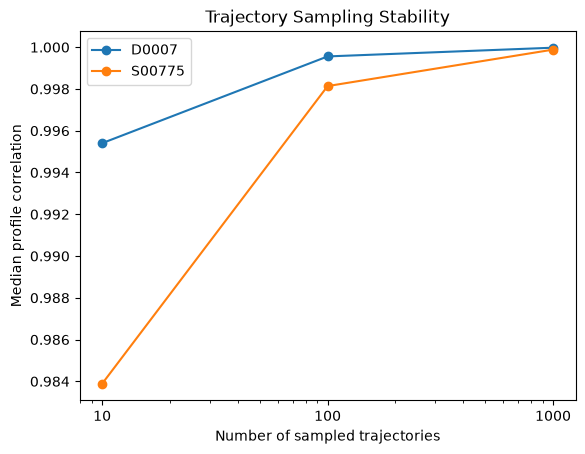

In [15]:
import matplotlib.pyplot as plt

plot_df = common_summary_df.copy()

for subject in plot_df["subject"].unique():
    subject_df = plot_df[plot_df["subject"] == subject].sort_values("sample_n")
    
    plt.plot(
        subject_df["sample_n"],
        subject_df["median_correlation"],
        marker="o",
        label=subject,
    )

plt.xscale("log")
plt.xticks([10, 100, 1000], ["10", "100", "1000"])
plt.xlabel("Number of sampled trajectories")
plt.ylabel("Median profile correlation")
plt.title("Trajectory Sampling Stability")
plt.legend()
plt.show()

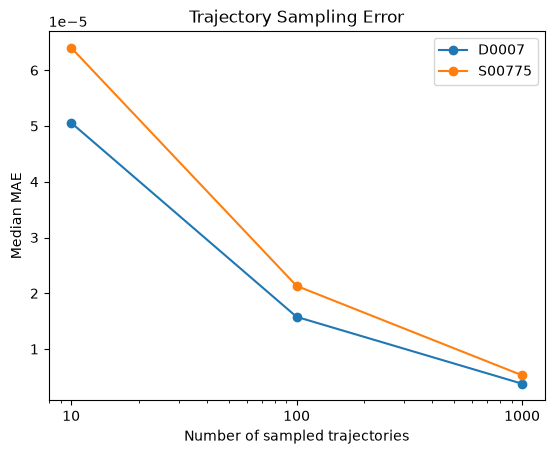

In [16]:
import matplotlib.pyplot as plt

plot_df = common_summary_df.copy()

for subject in plot_df["subject"].unique():
    subject_df = plot_df[plot_df["subject"] == subject].sort_values("sample_n")

    plt.plot(
        subject_df["sample_n"],
        subject_df["median_mae"],
        marker="o",
        label=subject,
    )

plt.xscale("log")
plt.xticks([10, 100, 1000], ["10", "100", "1000"])

plt.xlabel("Number of sampled trajectories")
plt.ylabel("Median MAE")
plt.title("Trajectory Sampling Error")

plt.legend()
plt.show()

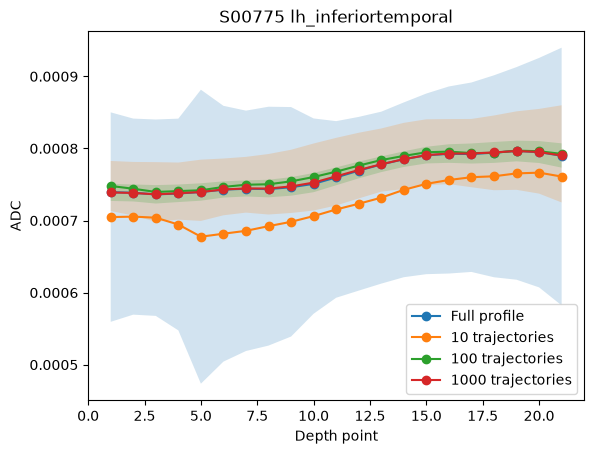

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


SUBJECT = "S00775"
HEMISPHERE = "lh"
REGION = "inferiortemporal"

PROFILE_DIR = SUBJECTS[SUBJECT]
FILE_PATH = PROFILE_DIR / f"{SUBJECT}_{HEMISPHERE}_{REGION}_{METRIC}.csv"

values = load_profile(FILE_PATH)

total_trajectories = values.shape[0]
n_depths = values.shape[1]
depth_index = np.arange(1, n_depths + 1)

full_profile = values.mean(axis=0)

rng = np.random.default_rng(RANDOM_SEED)

sampled_profile_summary = {}

for sample_n in SAMPLE_SIZES:
    if sample_n > total_trajectories:
        continue

    sampled_profiles = []

    for repeat in range(N_REPEATS):
        indices = rng.choice(
            total_trajectories,
            size=sample_n,
            replace=False,
        )

        sample_profile = values[indices].mean(axis=0)
        sampled_profiles.append(sample_profile)

    sampled_profiles = np.asarray(sampled_profiles)

    sampled_profile_summary[sample_n] = {
        "mean": sampled_profiles.mean(axis=0),
        "std": sampled_profiles.std(axis=0),
    }


plt.plot(
    depth_index,
    full_profile,
    marker="o",
    label="Full profile",
)

for sample_n in sorted(sampled_profile_summary):
    mean_profile = sampled_profile_summary[sample_n]["mean"]
    std_profile = sampled_profile_summary[sample_n]["std"]

    plt.plot(
        depth_index,
        mean_profile,
        marker="o",
        label=f"{sample_n} trajectories",
    )

    plt.fill_between(
        depth_index,
        mean_profile - std_profile,
        mean_profile + std_profile,
        alpha=0.2,
    )

plt.xlabel("Depth point")
plt.ylabel("ADC")
plt.title(f"{SUBJECT} {HEMISPHERE}_{REGION}")
plt.legend()
plt.show()